In [12]:
library(ggplot2)
library(dplyr)

healthcareData = read.csv("D:\\WGU\\Data_Preparation\\Health Insurance Dataset.csv")
summary(healthcareData)
head(healthcareData, 20)

      age            sex                 bmi            height     
 Min.   :18.00   Length:1338        Min.   :15.96   Min.   :54.28  
 1st Qu.:27.00   Class :character   1st Qu.:26.30   1st Qu.:63.82  
 Median :39.00   Mode  :character   Median :30.40   Median :66.60  
 Mean   :39.21                      Mean   :30.66   Mean   :66.61  
 3rd Qu.:51.00                      3rd Qu.:34.69   3rd Qu.:69.47  
 Max.   :64.00                      Max.   :53.13   Max.   :79.58  
    children        smoker             region             charges     
 Min.   :0.000   Length:1338        Length:1338        Min.   : 1122  
 1st Qu.:0.000   Class :character   Class :character   1st Qu.: 4740  
 Median :1.000   Mode  :character   Mode  :character   Median : 9382  
 Mean   :1.095                                         Mean   :13270  
 3rd Qu.:2.000                                         3rd Qu.:16640  
 Max.   :5.000                                         Max.   :63770  
    Level               sco

,age,sex,bmi,height,children,smoker,region,charges,Level,score
,<int>,<chr>,<dbl>,<dbl>,<int>,<chr>,<chr>,<dbl>,<chr>,<int>
1,19,female,27.90,64.03,0,yes,southwest,16884.92,B,72
2,31,female,25.74,66.63,0,no,southeast,3756.62,B,71
3,46,female,33.44,61.39,1,no,southeast,8240.59,B,88
4,37,female,27.74,63.62,3,no,northwest,7281.51,B,40
5,60,female,25.84,68.64,0,no,northwest,28923.14,B,38
6,62,female,26.29,64.89,0,yes,southeast,27808.73,D,40
7,56,female,39.82,61.13,0,no,southeast,11090.72,A,78
8,52,female,30.78,62.59,1,no,northeast,10797.34,C,88
9,60,female,36.01,65.44,0,no,northeast,13228.85,D,66


## The 4 variables I will select will be region, bmi, age, and levels. Let's begin with numerical data

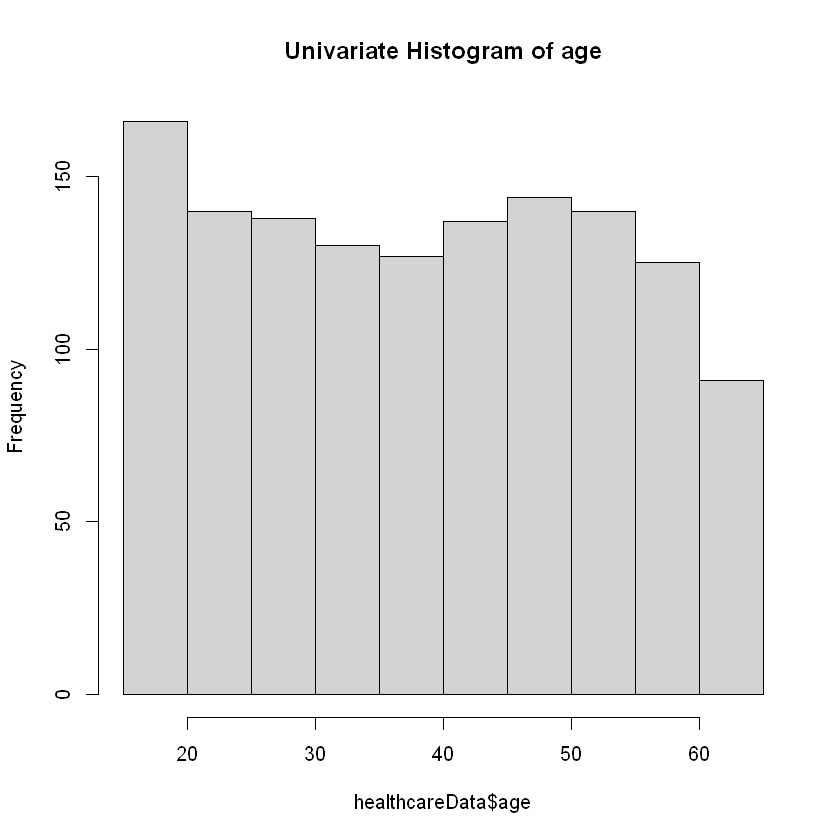

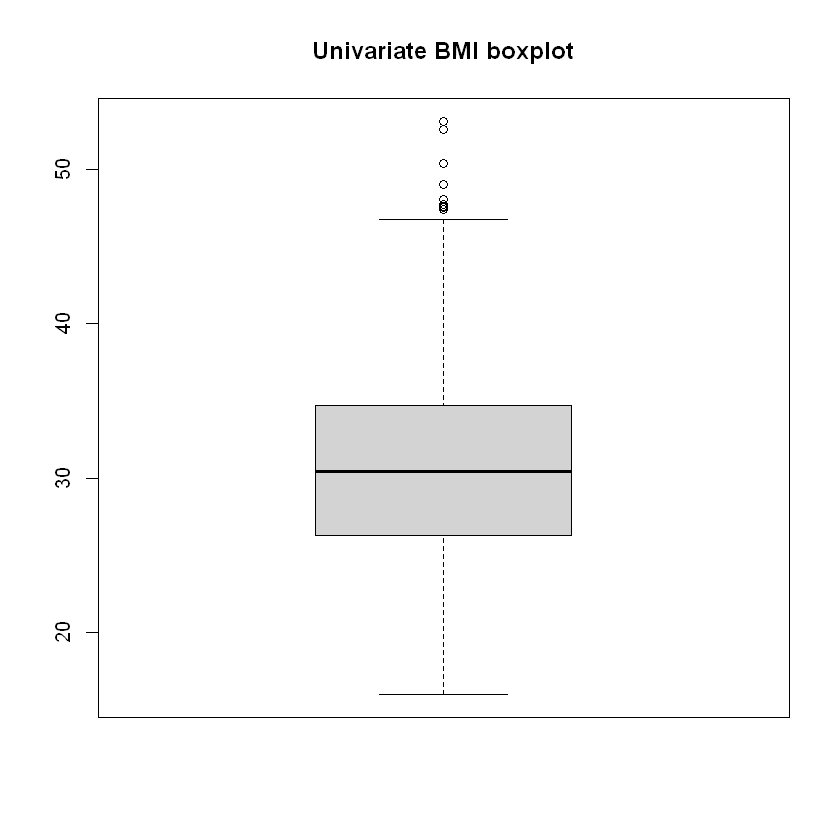

In [13]:
#For our quantitative variables, we can use a histogram
hist(healthcareData$age, main = "Univariate Histogram of age")

#Or a density
boxplot(healthcareData$bmi, main = "Univariate BMI boxplot")

## Categorical now, let's get a little bit fancy with ggplot

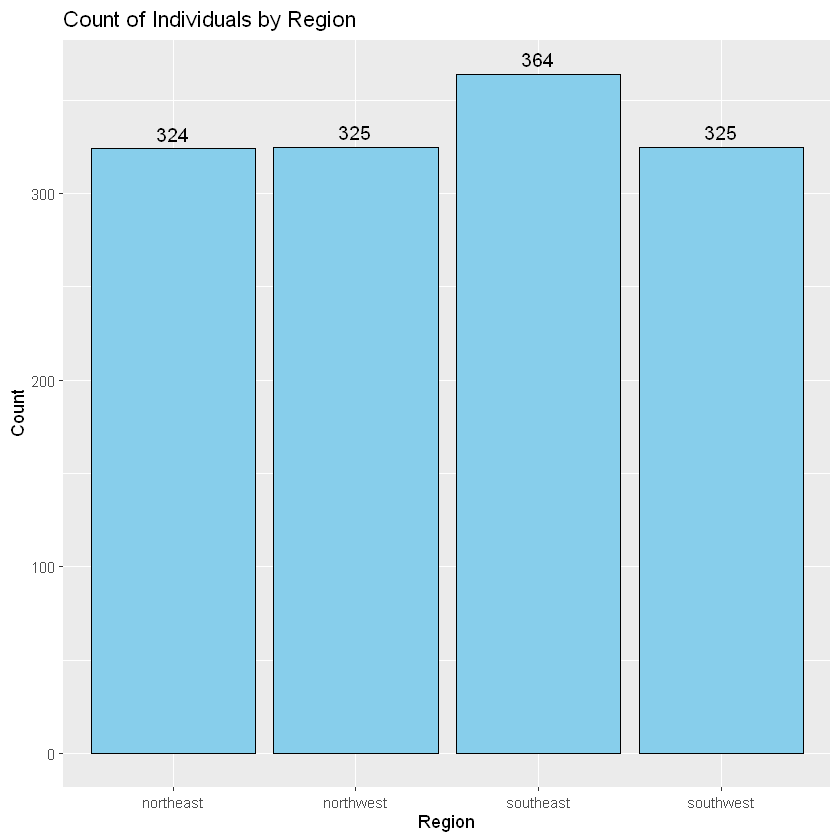

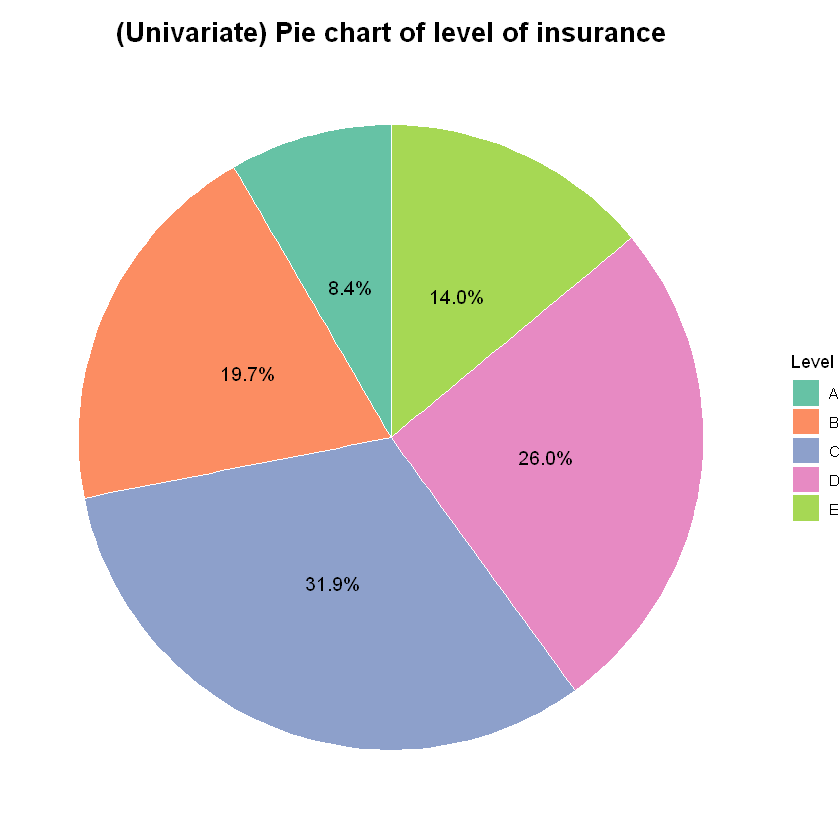

In [14]:
#histogram could be used for categorical too but needs the assistance of ggplot, definitely considered a bar graph
ggplot(healthcareData, aes(x = region)) +
  geom_bar(fill = "skyblue", color = "black") +
  geom_text(
    stat = "count",
    aes(label = ..count..),
    vjust = -0.5,
    size = 4
  ) +
  labs(
    title = "Count of Individuals by Region",
    x = "Region",
    y = "Count"
  )

#A pie chart can also be used
ggplot(healthcareData, aes(x = "", fill = Level)) +
  geom_bar(width = 1, color = "white") +
  geom_text(
    aes(label = scales::percent(..count../sum(..count..))),
    stat = "count",
    position = position_stack(vjust = 0.5),
    size = 4
  ) +
  coord_polar(theta = "y") +
  scale_fill_brewer(palette = "Set2") +
  labs(title = "(Univariate) Pie chart of level of insurance", fill = "Level") +
  theme_void() +
  theme(
    plot.title = element_text(hjust = 0.5, size = 16, face = "bold")
  )

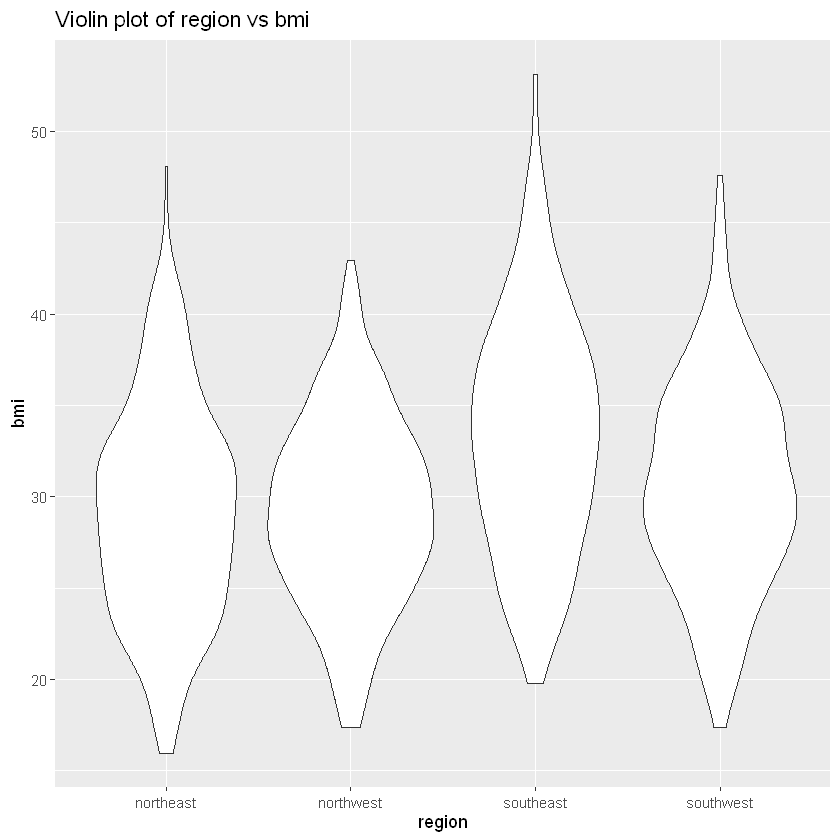

In [15]:
#Violin plot
# Ensure the categorical variable is a factor
healthcareDataCopy = healthcareData
healthcareDataCopy$region <- as.factor(healthcareData$region)

# Create the basic violin plot
ggplot(data = healthcareDataCopy, aes(x = region, y = bmi)) +
  geom_violin() + 
  ggtitle("Violin plot of region vs bmi")

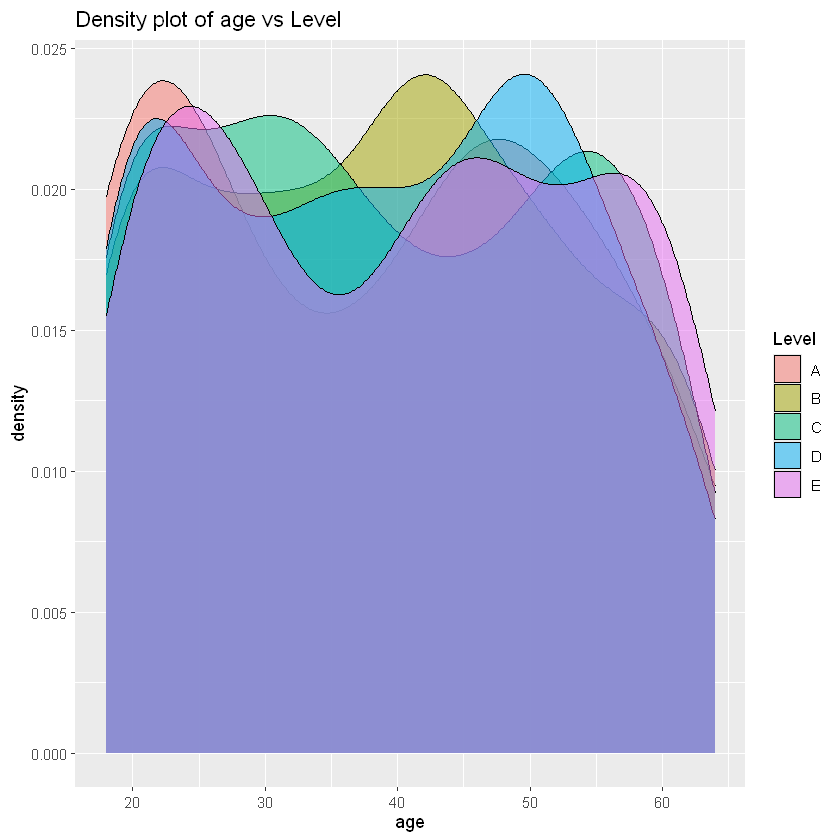

In [16]:
# using the 'iris' dataset
ggplot(healthcareDataCopy, aes(x = age, fill = Level)) +
  geom_density(alpha = 0.5) + # Use alpha for transparency where plots overlap
  labs(title = "Density plot of age vs Level")


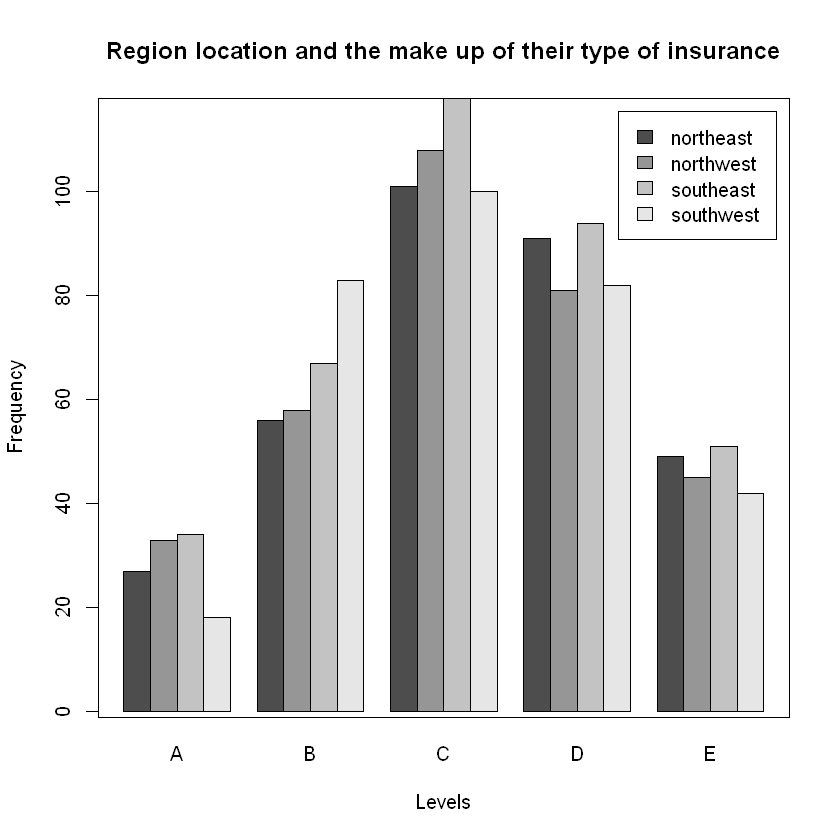

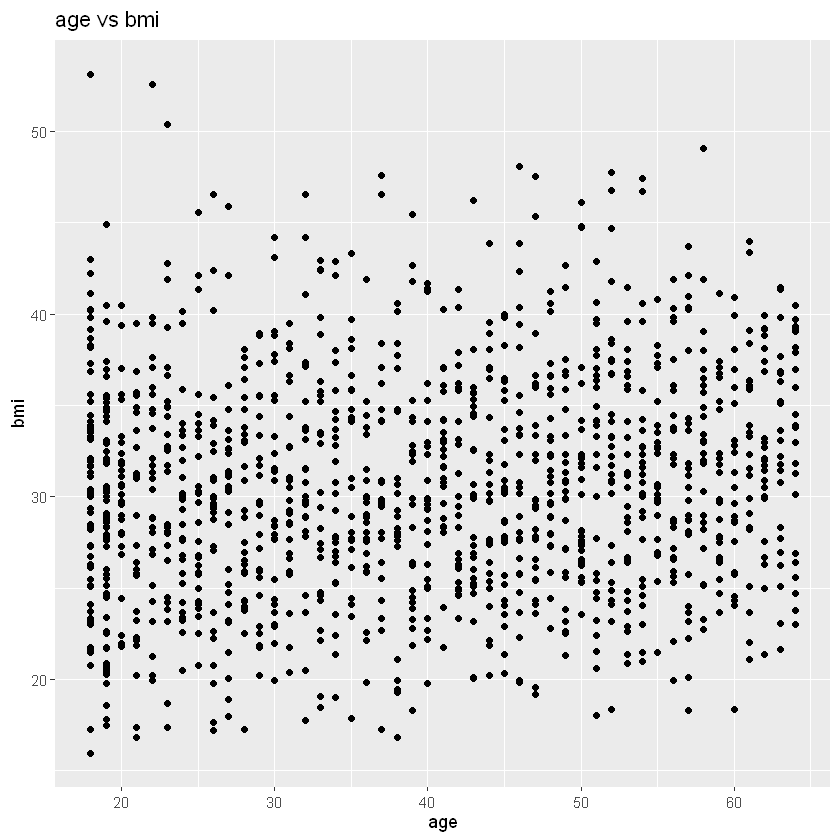

In [13]:
# Let's use a barplot to visualize categorical v categorical relationships (https://019b2dbc-0ac6-3185-aa9f-0bea50e3da6d.share.connect.posit.cloud/categorical-vs-categorical-clustered-bar-charts.html)
barplot(table(healthcareData$region, healthcareData$Level),
        beside = T,
        legend.text = T,
        xlab = "Levels",
        ylab = "Frequency",
        main = "Region location and the make up of their type of insurance")
# Add a box around the plot
box()

#For numerical scatterplot
ggplot(healthcareData, 
       aes(x = age, y = bmi)) +
  geom_point() + 
  labs(title = "age vs bmi")

# Let's find the mean, median, range, standard deviation, variance, percentiles, and quartiles for all the numerical data

In [14]:
numeric_summary <- healthcareData %>%
  summarise(across(
    .cols = where(is.numeric),
    .fns = list(
      mean       = ~mean(.x, na.rm = TRUE),
      median     = ~median(.x, na.rm = TRUE),
      min        = ~min(.x, na.rm = TRUE),
      max        = ~max(.x, na.rm = TRUE),
      range      = ~max(.x, na.rm = TRUE) - min(.x, na.rm = TRUE),
      sd         = ~sd(.x, na.rm = TRUE),
      variance   = ~var(.x, na.rm = TRUE),
      p25        = ~quantile(.x, 0.25, na.rm = TRUE),
      p50        = ~quantile(.x, 0.50, na.rm = TRUE),
      p75        = ~quantile(.x, 0.75, na.rm = TRUE)
    ),
    .names = "{.col}_{.fn}"
  ))

print(numeric_summary)

  age_mean age_median age_min age_max age_range   age_sd age_variance age_p25
1 39.20703         39      18      64        46 14.04996     197.4014      27
  age_p50 age_p75 bmi_mean bmi_median bmi_min bmi_max bmi_range   bmi_sd
1      39      51 30.66399       30.4   15.96   53.13     37.17 6.098063
  bmi_variance  bmi_p25 bmi_p50  bmi_p75 height_mean height_median height_min
1     37.18637 26.29625    30.4 34.69375    66.60768      66.60196      54.28
  height_max height_range height_sd height_variance height_p25 height_p50
1    79.5784      25.2984   3.86721        14.95531   63.81667   66.60196
  height_p75 children_mean children_median children_min children_max
1   69.46598      1.094918               1            0            5
  children_range children_sd children_variance children_p25 children_p50
1              5    1.205493          1.453213            0            1
  children_p75 charges_mean charges_median charges_min charges_max
1            2     13270.42       9382.033 

In [15]:
#First identify all the categorical variables
categorical_vars <- healthcareData %>%
  select(where(~ is.character(.x) || is.factor(.x)))

#Find the counts of the values
categorical_summary <- categorical_vars %>%
  summarise(across(
    everything(),
    ~ list(
        counts = table(.x),
        percentages = prop.table(table(.x)) * 100
      ),
    .names = "{.col}"
  ))

#Print out the percentage of each variable by taking the frequency over the total of each variable
for (var in names(categorical_vars)) {
  #This handles the percentages based on the count
  counts <- table(categorical_vars[[var]])
  percentages <- prop.table(counts) * 100

  #This prints the values
  print(data.frame(
    Category = names(counts),
    Count = as.vector(counts),
    Percentage = round(as.vector(percentages), 2)
  ))
}

Warning message:
"Returning more (or less) than 1 row per `summarise()` group was deprecated in dplyr 1.1.0.
ℹ Please use `reframe()` instead.
ℹ When switching from `summarise()` to `reframe()`, remember that `reframe()` always returns an ungrouped data frame
  and adjust accordingly."


  Category Count Percentage
1   female   662      49.48
2     male   676      50.52
  Category Count Percentage
1       no  1064      79.52
2      yes   274      20.48
   Category Count Percentage
1 northeast   324      24.22
2 northwest   325      24.29
3 southeast   364      27.20
4 southwest   325      24.29
  Category Count Percentage
1        A   112       8.37
2        B   264      19.73
3        C   427      31.91
4        D   348      26.01
5        E   187      13.98


In [10]:
head(healthcareData)

,age,sex,bmi,height,children,smoker,region,charges,Level,score
,<int>,<chr>,<dbl>,<dbl>,<int>,<chr>,<chr>,<dbl>,<chr>,<int>
1,19,female,27.90,64.03,0,yes,southwest,16884.92,B,72
2,31,female,25.74,66.63,0,no,southeast,3756.62,B,71
3,46,female,33.44,61.39,1,no,southeast,8240.59,B,88
4,37,female,27.74,63.62,3,no,northwest,7281.51,B,40
5,60,female,25.84,68.64,0,no,northwest,28923.14,B,38
6,62,female,26.29,64.89,0,yes,southeast,27808.73,D,40


## Let's run Anova to find what predictors lead to a better health score

In [10]:
anova = aov(score ~ children + Level, data = healthcareData)
summary(anova)
print(anova)

              Df Sum Sq Mean Sq F value  Pr(>F)    
children       1   1158    1158   5.288  0.0216 *  
Level          4  17565    4391  20.057 4.7e-16 ***
Residuals   1332 291629     219                    
---
Signif. codes:  0 '***' 0.001 '**' 0.01 '*' 0.05 '.' 0.1 ' ' 1

Call:
   aov(formula = score ~ children + Level, data = healthcareData)

Terms:
                 children     Level Residuals
Sum of Squares    1157.76  17565.35 291629.44
Deg. of Freedom         1         4      1332

Residual standard error: 14.79666
Estimated effects may be unbalanced


## Let's run a chi square test for our variables regions and level

In [12]:
data_table = table(healthcareData$Level, healthcareData$region)

chi_test = chisq.test(data_table)
summary(chi_test)
print(chi_test)

          Length Class  Mode     
statistic  1     -none- numeric  
parameter  1     -none- numeric  
p.value    1     -none- numeric  
method     1     -none- character
data.name  1     -none- character
observed  20     table  numeric  
expected  20     -none- numeric  
residuals 20     table  numeric  
stdres    20     table  numeric  


	Pearson's Chi-squared test

data:  data_table
X-squared = 13.933, df = 12, p-value = 0.305

